In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load the retail dataset

file_path = r"C:\Users\hi\Desktop\Smart_Retail_Data_Mining/data/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (541909, 8)


In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 541909
Columns: 8


In [8]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [10]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5268


In [12]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))

Original rows: 541909
Rows after removing duplicates: 536641
Duplicates removed: 5268


In [13]:
df_clean = df_clean.dropna(subset=["CustomerID"])

print("Rows after removing missing CustomerID:", len(df_clean))
print("Remaining missing CustomerID:", df_clean["CustomerID"].isnull().sum())

Rows after removing missing CustomerID: 401604
Remaining missing CustomerID: 0


In [14]:
df_clean = df_clean.dropna(subset=["Description"])

print("Rows after removing missing descriptions:", len(df_clean))

Rows after removing missing descriptions: 401604


In [15]:
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Rows after removing invalid transactions:", len(df_clean))

Rows after removing invalid transactions: 392692


In [16]:
df_clean["TotalAmount"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print(df_clean[["Quantity", "UnitPrice", "TotalAmount"]].head())

   Quantity  UnitPrice  TotalAmount
0         6       2.55        15.30
1         6       3.39        20.34
2         8       2.75        22.00
3         6       3.39        20.34
4         6       3.39        20.34


In [17]:
print("Final cleaned dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

Final cleaned dataset shape: (392692, 9)

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

Duplicate rows:
0


In [18]:
total_revenue = df_clean["TotalAmount"].sum()

print(f"Total Revenue: £{total_revenue:,.2f}")

Total Revenue: £8,887,208.89


In [19]:
unique_customers = df_clean["CustomerID"].nunique()

print("Unique Customers:", unique_customers)

Unique Customers: 4338


In [20]:
unique_products = df_clean["StockCode"].nunique()

print("Unique Products:", unique_products)

Unique Products: 3665


In [21]:
top_products = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


In [22]:
top_countries = (
    df_clean["Country"]
    .value_counts()
    .head(10)
)

print(top_countries)

Country
United Kingdom    349203
Germany             9025
France              8326
EIRE                7226
Spain               2479
Netherlands         2359
Belgium             2031
Switzerland         1841
Portugal            1453
Australia           1181
Name: count, dtype: int64


In [23]:
country_revenue = (
    df_clean.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_revenue)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalAmount, dtype: float64


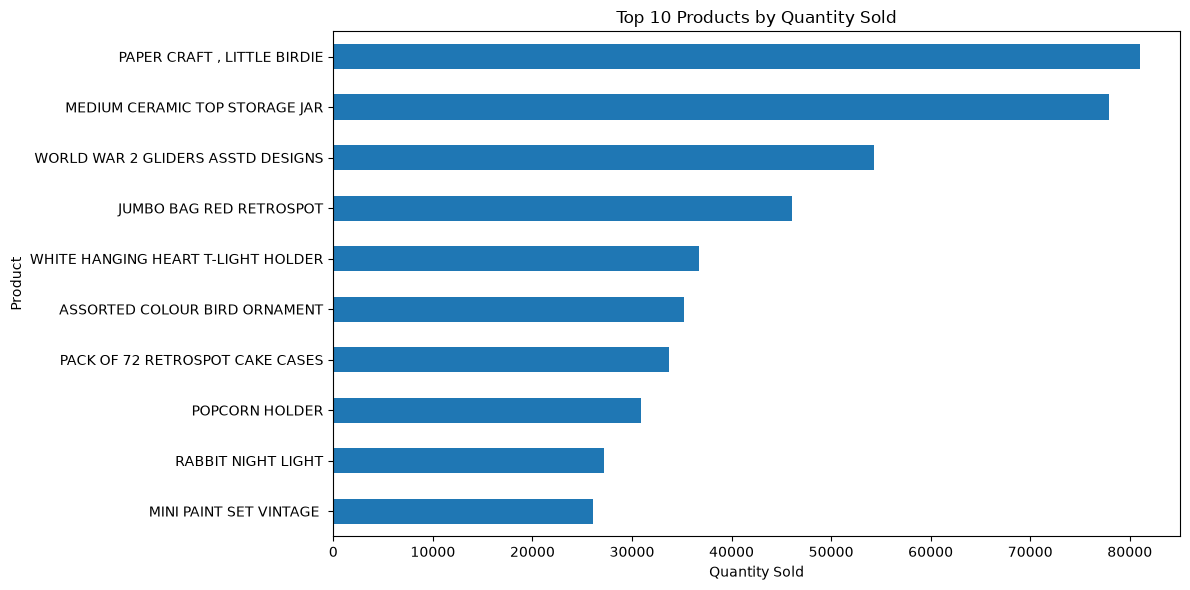

In [24]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

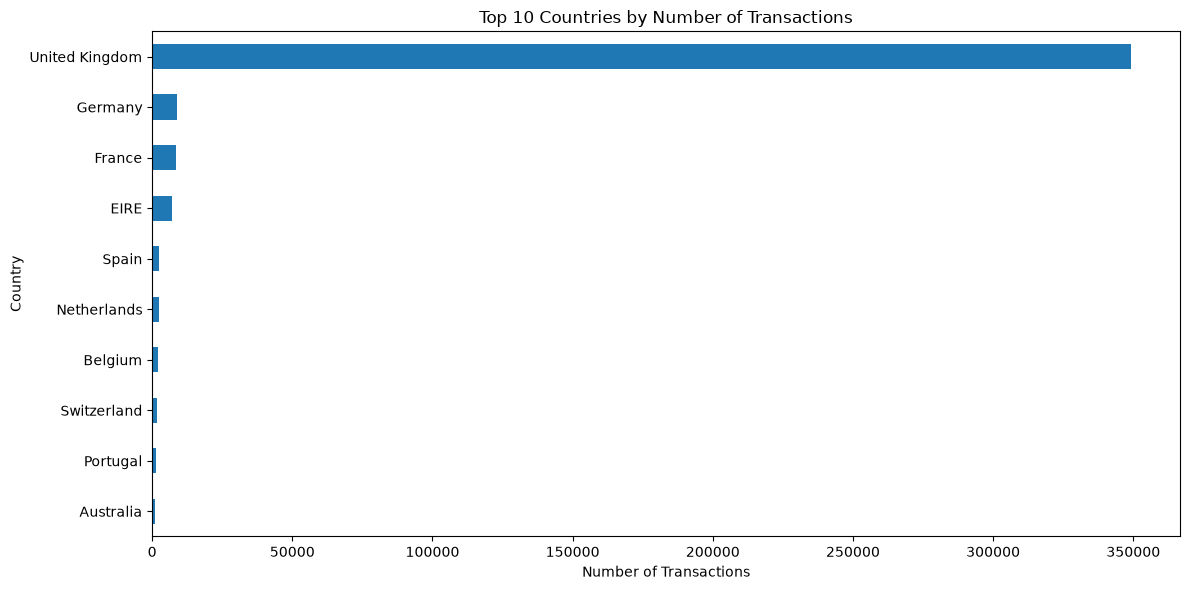

In [25]:
plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [26]:
latest_date = df_clean["InvoiceDate"].max()

print("Latest transaction date:", latest_date)

Latest transaction date: 2011-12-09 12:50:00


In [27]:
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40


In [28]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [29]:
print("Missing values:")
print(rfm.isnull().sum())

print("\nNegative values:")
print((rfm < 0).sum())

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Negative values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


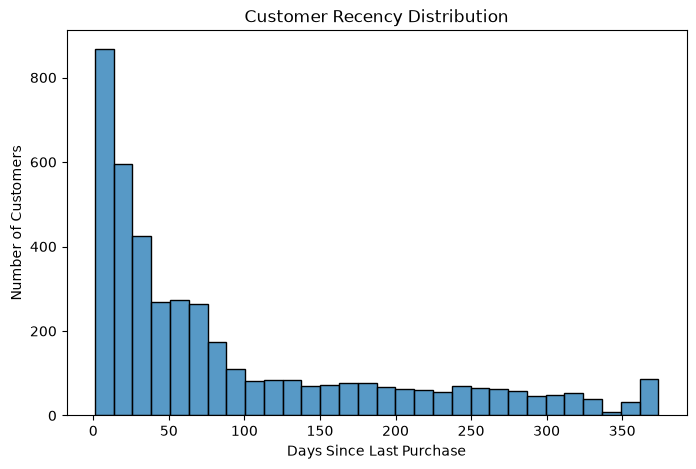

In [30]:
plt.figure(figsize=(8, 5))
sns.histplot(rfm["Recency"], bins=30)
plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.show()

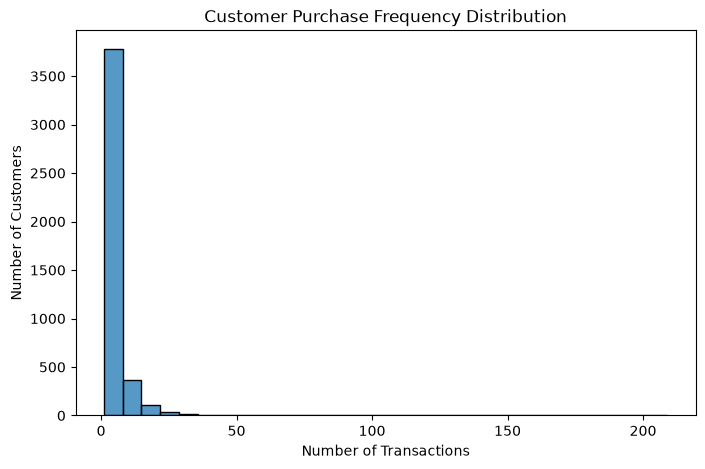

In [31]:
plt.figure(figsize=(8, 5))
sns.histplot(rfm["Frequency"], bins=30)
plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.show()

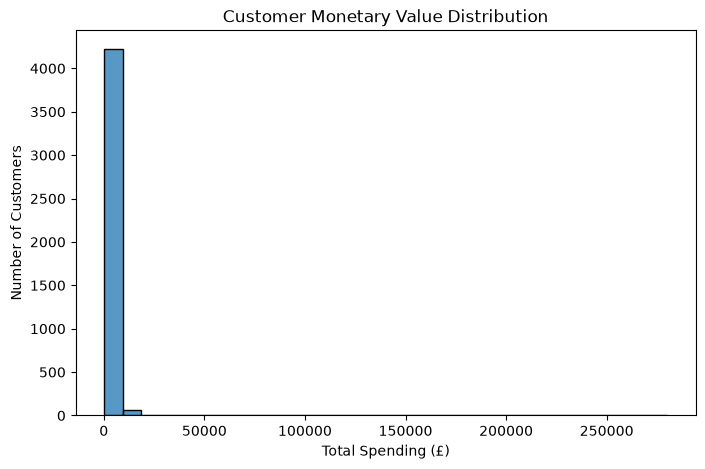

In [32]:
plt.figure(figsize=(8, 5))
sns.histplot(rfm["Monetary"], bins=30)
plt.title("Customer Monetary Value Distribution")
plt.xlabel("Total Spending (£)")
plt.ylabel("Number of Customers")
plt.show()

In [33]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [35]:
rfm_log = np.log1p(rfm)

print(rfm_log.head())

             Recency  Frequency   Monetary
CustomerID                                
12346.0     5.789960   0.693147  11.253955
12347.0     1.098612   2.079442   8.368925
12348.0     4.330733   1.609438   7.494564
12349.0     2.995732   0.693147   7.472245
12350.0     5.739793   0.693147   5.815324


In [36]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    index=rfm.index,
    columns=rfm.columns
)

print(rfm_scaled.head())

             Recency  Frequency  Monetary
CustomerID                               
12346.0     1.461993  -0.955214  3.707716
12347.0    -2.038734   1.074425  1.414903
12348.0     0.373104   0.386304  0.720024
12349.0    -0.623086  -0.955214  0.702287
12350.0     1.424558  -0.955214 -0.614514


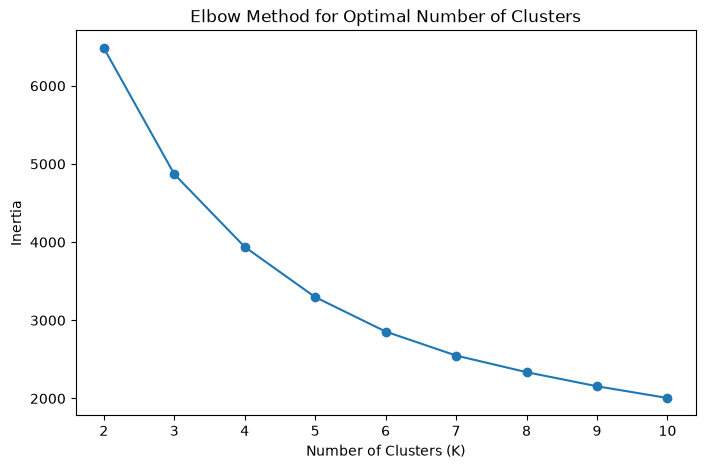

In [37]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(K_range, inertia, marker="o")

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.show()

In [38]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,3
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,3
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,2


In [40]:
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
})

cluster_summary["CustomerCount"] = rfm.groupby("Cluster").size()

cluster_summary

cluster_summary

,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,26.988010,1.641487,389.578189,834
1,18.514925,5.839019,2179.404542,938
2,208.350703,1.210918,277.219711,1209
3,103.663065,3.132613,1452.360946,1018
4,12.162242,20.746313,13877.159735,339


In [41]:
segment_names = {
    0: "Recent Low-Value",
    1: "Loyal Customers",
    2: "At-Risk / Inactive",
    3: "Potential Loyal Customers",
    4: "VIP / High-Value"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

rfm.head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346.0,326,1,77183.60,3,Potential Loyal Customers
12347.0,2,7,4310.00,1,Loyal Customers
12348.0,75,4,1797.24,3,Potential Loyal Customers
12349.0,19,1,1757.55,0,Recent Low-Value
12350.0,310,1,334.40,2,At-Risk / Inactive


In [42]:
rfm["Segment"].value_counts()

Segment
At-Risk / Inactive           1209
Potential Loyal Customers    1018
Loyal Customers               938
Recent Low-Value              834
VIP / High-Value              339
Name: count, dtype: int64

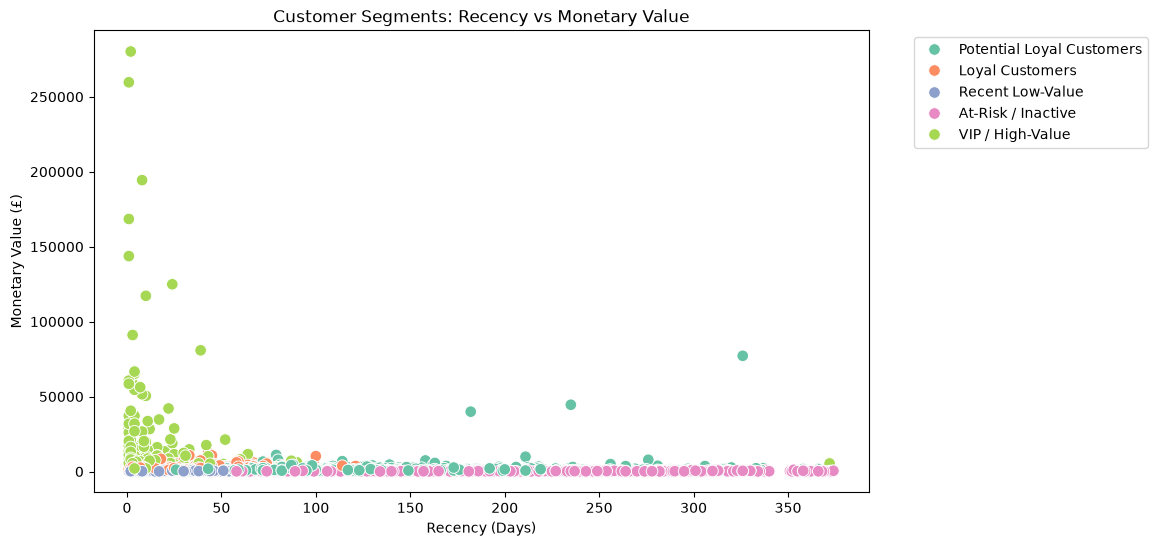

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Segment",
    palette="Set2",
    s=70
)

plt.title("Customer Segments: Recency vs Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (£)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

In [44]:
from mlxtend.frequent_patterns import apriori, association_rules

In [45]:
uk_data = df_clean[df_clean["Country"] == "United Kingdom"].copy()

basket = (
    uk_data.groupby(["InvoiceNo", "Description"])["Quantity"]
    .sum()
    .unstack()
    .fillna(0)
)

basket = basket.map(lambda x: 1 if x > 0 else 0)

basket.head()

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,TOADSTOOL BEDSIDE LIGHT,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [46]:
frequent_itemsets = apriori(
    basket,
    min_support=0.02,
    use_colnames=True
)

frequent_itemsets.sort_values(
    by="support",
    ascending=False
).head(20)

c:\Users\hi\Desktop\Smart_Retail_Data_Mining\venv\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
184,0.113180,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
79,0.086928,frozenset({JUMBO BAG RED RETROSPOT})
149,0.084705,frozenset({REGENCY CAKESTAND 3 TIER})
11,0.078097,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
123,0.077496,frozenset({PARTY BUNTING})
101,0.067283,frozenset({LUNCH BAG RED RETROSPOT})
159,0.060495,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN })
94,0.059834,frozenset({LUNCH BAG BLACK SKULL.})
119,0.056770,frozenset({PAPER CHAIN KIT 50'S CHRISTMAS })
108,0.056350,frozenset({NATURAL SLATE HEART CHALKBOARD })


In [47]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.3
)

rules = rules.sort_values(
    by="lift",
    ascending=False
)

rules.head(20)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
65,frozenset({GREEN REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",0.036766,0.023009,0.020485,0.557190,24.216650,1.0,0.019639,2.206342,0.995299,0.521407,0.546761,0.723764
62,"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.023009,0.036766,0.020485,0.890339,24.216650,1.0,0.019639,8.783780,0.981284,0.521407,0.886154,0.723764
64,frozenset({PINK REGENCY TEACUP AND SAUCER}),"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",0.029617,0.028595,0.020485,0.691684,24.188581,1.0,0.019638,3.150674,0.987917,0.542994,0.682608,0.704035
63,"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",frozenset({PINK REGENCY TEACUP AND SAUCER}),0.028595,0.029617,0.020485,0.716387,24.188581,1.0,0.019638,3.421500,0.986878,0.542994,0.707730,0.704035
5,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.036766,0.029617,0.024270,0.660131,22.289120,1.0,0.023181,2.855166,0.991592,0.576320,0.649758,0.739802
4,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.029617,0.036766,0.024270,0.819473,22.289120,1.0,0.023181,5.335669,0.984286,0.576320,0.812582,0.739802
61,"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",frozenset({ROSES REGENCY TEACUP AND SAUCER }),0.024270,0.040731,0.020485,0.844059,20.723028,1.0,0.019497,6.151506,0.975418,0.460189,0.837438,0.673505
66,frozenset({ROSES REGENCY TEACUP AND SAUCER }),"frozenset({PINK REGENCY TEACUP AND SAUCER, GRE...",0.040731,0.024270,0.020485,0.502950,20.723028,1.0,0.019497,1.963041,0.992155,0.460189,0.490586,0.673505
6,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({ROSES REGENCY TEACUP AND SAUCER }),0.036766,0.040731,0.028595,0.777778,19.095706,1.0,0.027098,4.316713,0.983802,0.584767,0.768342,0.739921
7,frozenset({ROSES REGENCY TEACUP AND SAUCER }),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.040731,0.036766,0.028595,0.702065,19.095706,1.0,0.027098,3.233034,0.987869,0.584767,0.690693,0.739921


In [48]:
rules_display = rules.copy()

rules_display["antecedents"] = rules_display["antecedents"].apply(
    lambda x: ", ".join(x)
)

rules_display["consequents"] = rules_display["consequents"].apply(
    lambda x: ", ".join(x)
)

rules_display[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(15)

,antecedents,consequents,support,confidence,lift
65,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.020485,0.557190,24.216650
62,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.020485,0.890339,24.216650
64,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.020485,0.691684,24.188581
63,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.020485,0.716387,24.188581
5,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.024270,0.660131,22.289120
4,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.024270,0.819473,22.289120
61,"PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.020485,0.844059,20.723028
66,ROSES REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY ...",0.020485,0.502950,20.723028
6,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.028595,0.777778,19.095706
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.028595,0.702065,19.095706


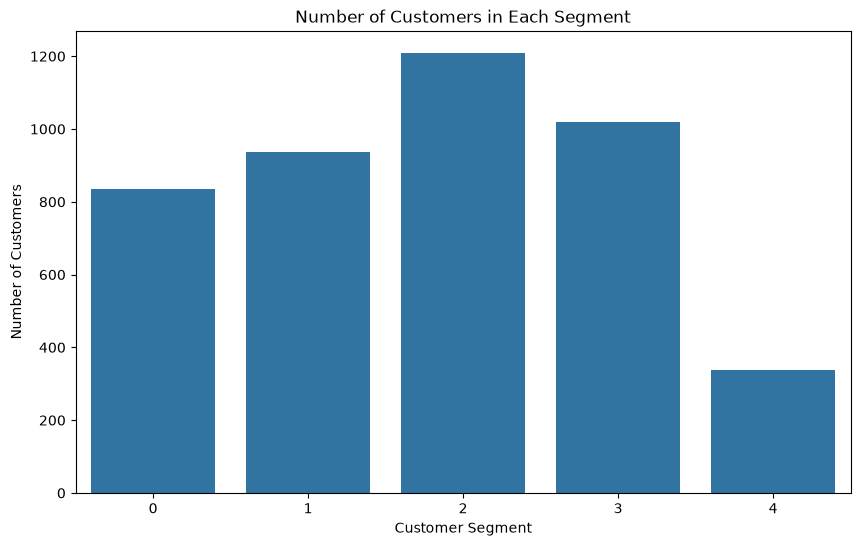

In [49]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cluster_summary.reset_index(),
    x="Cluster",
    y="CustomerCount"
)

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.show()

In [51]:
strong_rules = rules_display[
    (rules_display["confidence"] >= 0.5) &
    (rules_display["lift"] > 5)
].copy()

strong_rules = strong_rules.sort_values(
    by="lift",
    ascending=False
)

strong_rules.head(15)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
65,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.036766,0.023009,0.020485,0.557190,24.216650,1.0,0.019639,2.206342,0.995299,0.521407,0.546761,0.723764
62,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.023009,0.036766,0.020485,0.890339,24.216650,1.0,0.019639,8.783780,0.981284,0.521407,0.886154,0.723764
64,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.029617,0.028595,0.020485,0.691684,24.188581,1.0,0.019638,3.150674,0.987917,0.542994,0.682608,0.704035
63,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.028595,0.029617,0.020485,0.716387,24.188581,1.0,0.019638,3.421500,0.986878,0.542994,0.707730,0.704035
5,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.036766,0.029617,0.024270,0.660131,22.289120,1.0,0.023181,2.855166,0.991592,0.576320,0.649758,0.739802
4,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.029617,0.036766,0.024270,0.819473,22.289120,1.0,0.023181,5.335669,0.984286,0.576320,0.812582,0.739802
61,"PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.024270,0.040731,0.020485,0.844059,20.723028,1.0,0.019497,6.151506,0.975418,0.460189,0.837438,0.673505
66,ROSES REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY ...",0.040731,0.024270,0.020485,0.502950,20.723028,1.0,0.019497,1.963041,0.992155,0.460189,0.490586,0.673505
6,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.036766,0.040731,0.028595,0.777778,19.095706,1.0,0.027098,4.316713,0.983802,0.584767,0.768342,0.739921
7,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.040731,0.036766,0.028595,0.702065,19.095706,1.0,0.027098,3.233034,0.987869,0.584767,0.690693,0.739921


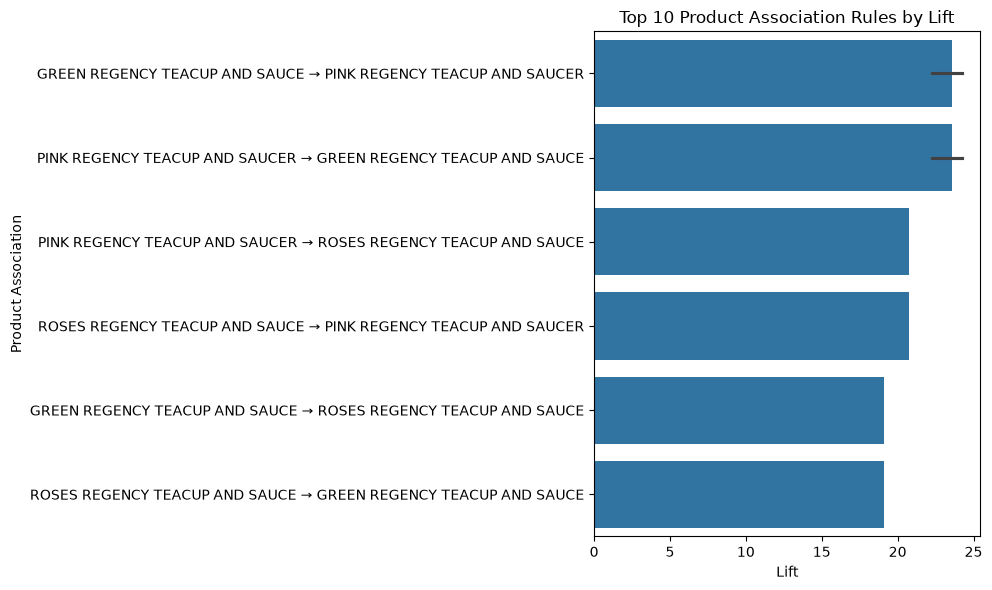

In [52]:
top_rules = strong_rules.head(10).copy()

top_rules["Rule"] = (
    top_rules["antecedents"].str[:30]
    + " → "
    + top_rules["consequents"].str[:30]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_rules,
    x="lift",
    y="Rule"
)

plt.title("Top 10 Product Association Rules by Lift")
plt.xlabel("Lift")
plt.ylabel("Product Association")
plt.tight_layout()
plt.show()

In [ ]:
# Save cleaned data
df_clean.to_csv("../data/cleaned_retail.csv", index=False)

# Save RFM customer segmentation
rfm.to_csv("../data/customer_segments.csv")

# Save RFM cluster summary
cluster_summary.to_csv("../data/cluster_summary.csv")

# Save strong association rules
strong_rules.to_csv("../data/association_rules.csv", index=False)

print("All analysis results saved successfully!")

All analysis results saved successfully!


: 